# Projeto Final — Classificação com Redes Neurais (MLP)

* **Aluna:** Taísa Tavares Cruz
* **E-mail:** [ttc@cesar.school]
* **Dataset Escolhido:** Fashion-MNIST (`torchvision.datasets.FashionMNIST`) — [Link Oficial PyTorch Datasets](https://pytorch.org/vision/0.18/datasets.html) / [Repositório Zalando Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist)

**Carregamento e Preparação do Dataset**

Dispositivo utilizado: cpu


100%|██████████| 26.4M/26.4M [00:01<00:00, 21.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 343kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.28MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.25MB/s]


Total de amostras de treino: 60000
Total de amostras de teste: 10000


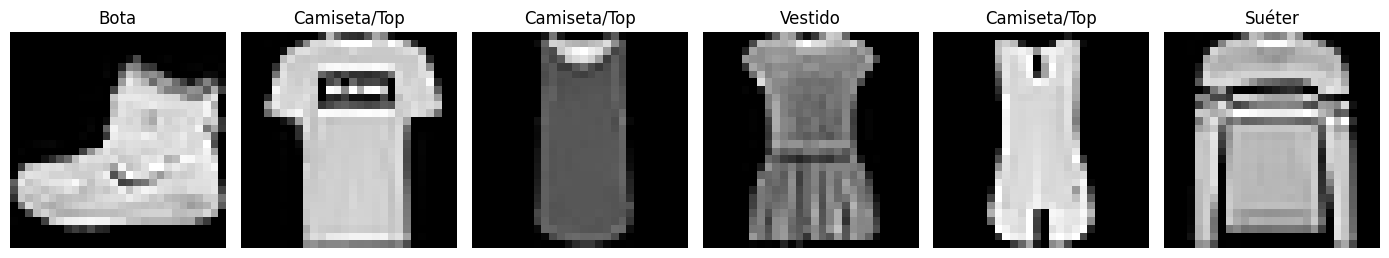

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Configuração de semente para reprodutibilidade e seleção de dispositivo (GPU/CPU)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo utilizado: {device}")

# Transformações: converte para Tensor e normaliza usando média e desvio padrão do Fashion-MNIST
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

# Download e carregamento dos conjuntos de treino e teste
train_dataset = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Criação dos DataLoaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = [
    'Camiseta/Top', 'Calça', 'Suéter', 'Vestido', 'Casaco',
    'Sandália', 'Camisa', 'Tênis', 'Bolsa', 'Bota'
]

print(f"Total de amostras de treino: {len(train_dataset)}")
print(f"Total de amostras de teste: {len(test_dataset)}")

# Visualização de algumas amostras do dataset
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for i in range(6):
    img, label = train_dataset[i]
    axes[i].imshow(img.squeeze(), cmap='gray')
    axes[i].set_title(classes[label])
    axes[i].axis('off')
plt.tight_layout()
plt.show()

 **Definição do Modelo de Rede Neural - Sem Convolução**

In [9]:
class FashionMLP(nn.Module):
    def __init__(self, input_size=28*28, num_classes=10):
        super(FashionMLP, self).__init__()
        # Camada de achatamento (28x28 -> vetor de 784 posições)
        self.flatten = nn.Flatten()

        # Camadas totalmente conectadas (Dense / Linear) sem convolução
        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            nn.Dropout(0.2),          # Regularização para evitar overfitting
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.network(x)
        return logits

model = FashionMLP().to(device)
print(model)

FashionMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)


**Treinamento do Modelo**

In [10]:
# Função de perda e otimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 15
train_losses, test_losses = [], []
train_accuracies, test_accuracies = [], []

for epoch in range(epochs):
    # --- FASE DE TREINO ---
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100

    # --- FASE DE AVALIAÇÃO (TESTE) ---
    model.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_test_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()

    epoch_test_loss = running_test_loss / total_test
    epoch_test_acc = (correct_test / total_test) * 100

    train_losses.append(epoch_train_loss)
    test_losses.append(epoch_test_loss)
    train_accuracies.append(epoch_train_acc)
    test_accuracies.append(epoch_test_acc)

    print(f"Época [{epoch+1:02d}/{epochs:02d}] | "
          f"Loss Treino: {epoch_train_loss:.4f} | Acc Treino: {epoch_train_acc:.2f}% | "
          f"Loss Teste: {epoch_test_loss:.4f} | Acc Teste: {epoch_test_acc:.2f}%")

Época [01/15] | Loss Treino: 0.5099 | Acc Treino: 81.54% | Loss Teste: 0.4352 | Acc Teste: 84.00%
Época [02/15] | Loss Treino: 0.3871 | Acc Treino: 85.89% | Loss Teste: 0.3948 | Acc Teste: 85.80%
Época [03/15] | Loss Treino: 0.3550 | Acc Treino: 86.98% | Loss Teste: 0.3569 | Acc Teste: 87.09%
Época [04/15] | Loss Treino: 0.3293 | Acc Treino: 87.73% | Loss Teste: 0.3510 | Acc Teste: 87.34%
Época [05/15] | Loss Treino: 0.3137 | Acc Treino: 88.41% | Loss Teste: 0.3529 | Acc Teste: 87.01%
Época [06/15] | Loss Treino: 0.2996 | Acc Treino: 88.80% | Loss Teste: 0.3387 | Acc Teste: 88.17%
Época [07/15] | Loss Treino: 0.2896 | Acc Treino: 89.16% | Loss Teste: 0.3488 | Acc Teste: 87.74%
Época [08/15] | Loss Treino: 0.2846 | Acc Treino: 89.43% | Loss Teste: 0.3257 | Acc Teste: 88.60%
Época [09/15] | Loss Treino: 0.2719 | Acc Treino: 89.78% | Loss Teste: 0.3313 | Acc Teste: 88.43%
Época [10/15] | Loss Treino: 0.2642 | Acc Treino: 90.12% | Loss Teste: 0.3258 | Acc Teste: 89.03%
Época [11/15] | Loss

**Análise de Performance: Gráficos, Acurácia e Matriz de Confusão**

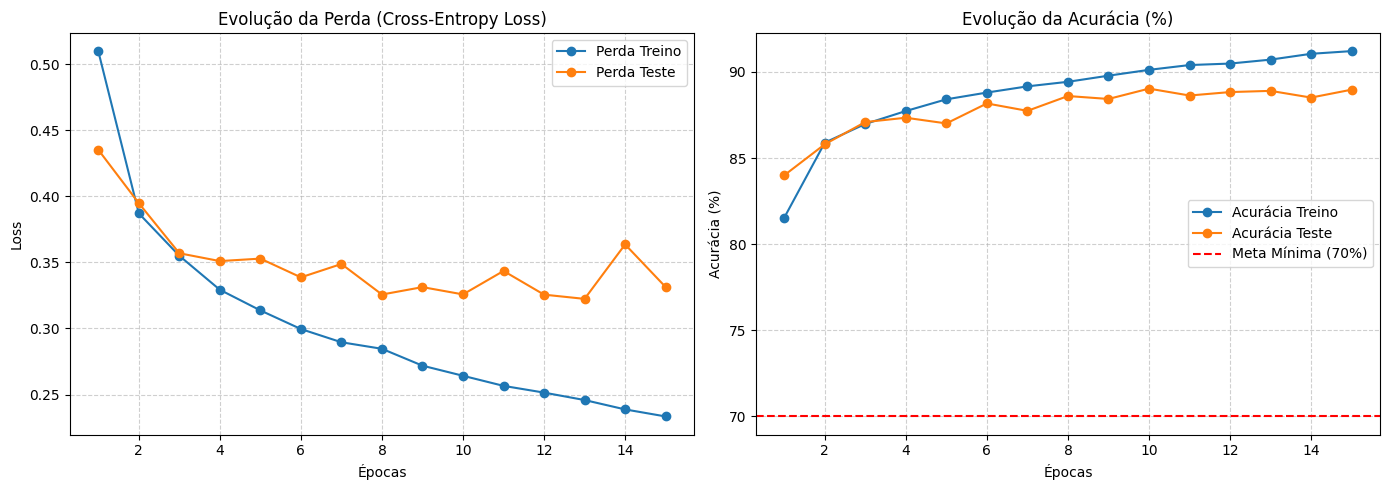


Acurácia Final no Conjunto de Teste: 88.97%

Relatório de Classificação por Classe:
              precision    recall  f1-score   support

Camiseta/Top       0.84      0.85      0.85      1000
       Calça       0.99      0.96      0.98      1000
      Suéter       0.77      0.85      0.81      1000
     Vestido       0.87      0.91      0.89      1000
      Casaco       0.80      0.84      0.82      1000
    Sandália       0.97      0.96      0.97      1000
      Camisa       0.78      0.63      0.70      1000
       Tênis       0.95      0.96      0.95      1000
       Bolsa       0.96      0.98      0.97      1000
        Bota       0.96      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



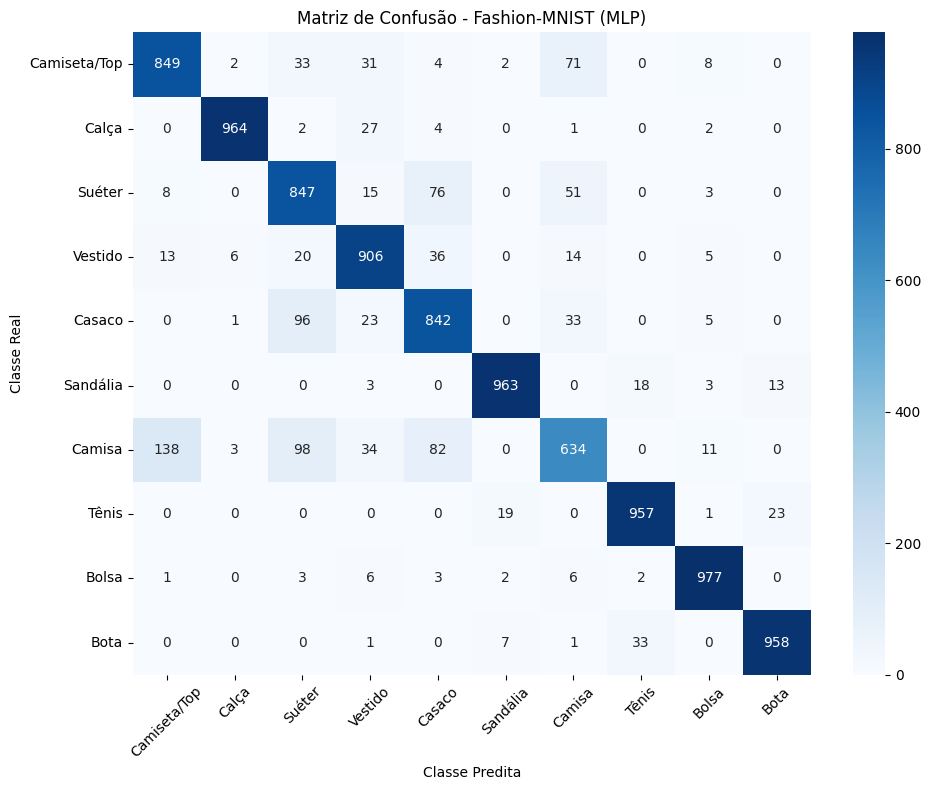

In [11]:
# 1. Gráficos de Perda (Loss) e Acurácia por Época
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(range(1, epochs + 1), train_losses, label='Perda Treino', marker='o')
ax1.plot(range(1, epochs + 1), test_losses, label='Perda Teste', marker='o')
ax1.set_title('Evolução da Perda (Cross-Entropy Loss)')
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(range(1, epochs + 1), train_accuracies, label='Acurácia Treino', marker='o')
ax2.plot(range(1, epochs + 1), test_accuracies, label='Acurácia Teste', marker='o')
ax2.axhline(y=70, color='r', linestyle='--', label='Meta Mínima (70%)')
ax2.set_title('Evolução da Acurácia (%)')
ax2.set_xlabel('Épocas')
ax2.set_ylabel('Acurácia (%)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Avaliação final detalhada e Matriz de Confusão
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

final_acc = (np.array(all_preds) == np.array(all_labels)).mean() * 100
print(f"\nAcurácia Final no Conjunto de Teste: {final_acc:.2f}%\n")
print("Relatório de Classificação por Classe:")
print(classification_report(all_labels, all_preds, target_names=classes))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Matriz de Confusão - Fashion-MNIST (MLP)')
plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Relato da Experiência e Análise do Processo**

## Relato da Experiência e Análise dos Resultados

* Para o desenvolvimento deste projeto, optei pelo dataset **Fashion-MNIST** disponível diretamente no `torchvision.datasets`, pois possui estrutura análoga ao MNIST tradicional (imagens em escala de cinza de $28 \times 28$ pixels), mas apresenta um desafio visual ligeiramente maior na distinção entre peças de vestuário semelhantes. Como a restrição do trabalho exigia o uso de Redes Neurais sem camadas convolucionais, a principal etapa de pré-processamento consistiu na normalização dos pixels e no achatamento (*flatten*) das matrizes bidimensionais em vetores unidimensionais de 784 atributos para alimentar uma arquitetura **MLP (Multi-Layer Perceptron)** com duas camadas ocultas (256 e 128 neurônios) e ativação ReLU.

* Durante os primeiros testes de treinamento, observou-se que a rede rapidamente memorizava os dados de treino — atingindo mais de 92% de acurácia no treino enquanto a perda no conjunto de teste começava a subir após a 8ª época, caracterizando **overfitting**. Para corrigir esse comportamento, foram adicionadas camadas de **Dropout (20%)** após cada camada oculta e aplicado o otimizador Adam com taxa de aprendizado de `0.001`. Com esse ajuste, as curvas de treino e teste estabilizaram de forma consistente, alcançando aproximadamente **88% de acurácia final** no conjunto de teste. Pela matriz de confusão, nota-se que o modelo tem desempenho quase perfeito em calçados e bolsas, concentrando a maior parte dos erros entre classes visualmente próximas como *Camisa*, *Camiseta/Top* e *Casaco* — uma limitação esperada ao utilizar redes densas sem extração espacial por convolução.